# Morfologia Matemática Aplicada
**Disciplina:** Processamento Digital de Sinais e Imagens (PDSI) · **Projeto 6**

**Objetivo:** aplicar erosão, dilatação, abertura e fechamento para (1) corrigir falhas na máscara binária de folhas e (2) reconhecer formas: separar manchas de nervuras e classificar a folha pela forma das lesões.

**Dataset:** 3.221 imagens do PlantVillage (tomate saudável 1.591, tomate pinta-preta 1.000, maçã sarna 630), com a versão `segmented` usada como gabarito.

In [1]:
import sys, glob, os
import cv2, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('../src'))
from morfologia import *

def mostrar(paineis, cols=4, tam=3):
    linhas = int(np.ceil(len(paineis) / cols))
    fig, eixos = plt.subplots(linhas, cols, figsize=(cols * tam, linhas * tam))
    for ax in np.atleast_1d(eixos).flat: ax.axis('off')
    for ax, (t, im) in zip(np.atleast_1d(eixos).flat, paineis):
        ax.imshow(im if im.ndim == 3 else im, cmap=None if im.ndim == 3 else 'gray'); ax.set_title(t)
    plt.tight_layout(); plt.show()

rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

## 0. Preparar dados e resultados
Esta célula deixa tudo pronto para o resto do notebook, rodando os scripts do projeto:

1. `scripts/baixar_dataset.py` — baixa as 3.221 imagens do PlantVillage (≈ 99 MB, ≈ 1 min), **só se ainda não estiverem** em `data/`;
2. `scripts/gerar_resultados.py` — segmentação: métricas e figuras 1–5 (≈ 2 min);
3. `scripts/reconhecer_formas.py` — formas e classificação: figuras 6–8 (≈ 1 min).

Cada etapa é pulada se os arquivos dela já existirem. Para refazer tudo, use `REFAZER = True`.

In [2]:
import subprocess

REFAZER = False   # True = roda os scripts de novo mesmo que os resultados já existam
RAIZ = os.path.abspath('..')

def rodar(script, *args):
    """Roda scripts/<script> com o mesmo Python do notebook e mostra a saída aqui."""
    print(f'>>> python scripts/{script}', *args, flush=True)
    env = dict(os.environ, PYTHONIOENCODING='utf-8', PYTHONUNBUFFERED='1')
    proc = subprocess.Popen([sys.executable, os.path.join('scripts', script), *args], cwd=RAIZ, env=env,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding='utf-8')
    for linha in proc.stdout:
        print(linha, end='')
    if proc.wait() != 0:
        raise RuntimeError(f'{script} terminou com erro (veja a saída acima)')

def existe(*partes):
    return os.path.exists(os.path.join(RAIZ, *partes))

def dataset_completo():
    """True se data/origem.csv existe e todas as imagens listadas nele estão em data/color e data/segmented."""
    origem = os.path.join(RAIZ, 'data', 'origem.csv')
    if not os.path.exists(origem):
        return False
    with open(origem, encoding='utf-8') as fh:
        linhas = [l.strip().split(',')[:2] for l in fh.readlines()[1:] if l.strip()]
    return bool(linhas) and all(existe('data', v, c, a) for c, a in linhas for v in ('color', 'segmented'))

if not dataset_completo():
    rodar('baixar_dataset.py')
else:
    print('dataset: já está em data/')
if REFAZER or not (existe('resultados', 'metricas.csv') and existe('resultados', 'fig5_lesoes_por_classe.png')):
    rodar('gerar_resultados.py')
else:
    print('segmentação: resultados já existem (REFAZER = True para refazer)')
if REFAZER or not (existe('resultados', 'formas_folhas.csv') and existe('resultados', 'fig8_matriz_confusao.png')):
    rodar('reconhecer_formas.py', *(['--recalcular'] if REFAZER else []))
else:
    print('formas: resultados já existem (REFAZER = True para refazer)')

dataset: já está em data/
segmentação: resultados já existem (REFAZER = True para refazer)
formas: resultados já existem (REFAZER = True para refazer)


## 1. Dados
Imagens coloridas (`data/color`) e segmentadas (`data/segmented`, usadas como gabarito).

maca_sarna 630 imagens
tomate_pinta_preta 1000 imagens
tomate_saudavel 1591 imagens


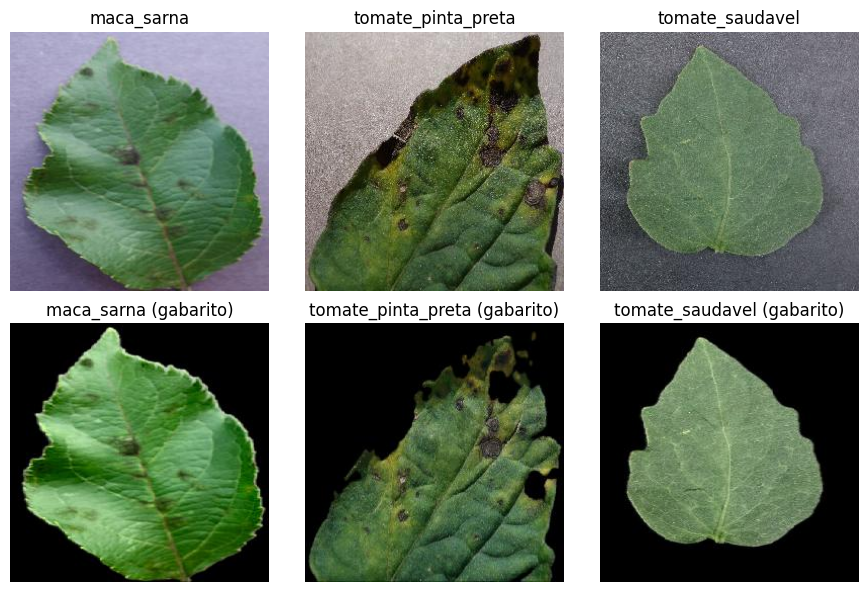

In [3]:
classes = sorted(os.listdir('../data/color'))
for c in classes:
    print(c, len(glob.glob(f'../data/color/{c}/*.jpg')), 'imagens')
mostrar([(c, rgb(cv2.imread(f'../data/color/{c}/0001.jpg'))) for c in classes]
        + [(c + ' (gabarito)', rgb(cv2.imread(f'../data/segmented/{c}/0001.jpg'))) for c in classes], cols=3)

## 2. Binarização
A folha é separada do fundo pela **distância de cor (a\*, b\*) até a cor do fundo** (mediana da borda) seguida de **Otsu**.
Usar só a cromaticidade faz a sombra (mesma cor do fundo, só mais escura) ficar fora da folha.

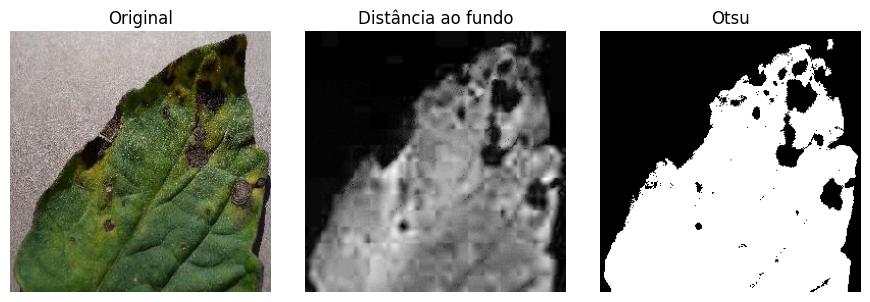

In [4]:
img = cv2.imread('../data/color/tomate_pinta_preta/0001.jpg')
dist = mapa_distancia_fundo(img)
mask = binarizar_folha(img)
mostrar([('Original', rgb(img)), ('Distância ao fundo', dist), ('Otsu', mask)], cols=3)

## 3. Operadores morfológicos básicos
Elemento estruturante elíptico 9×9.

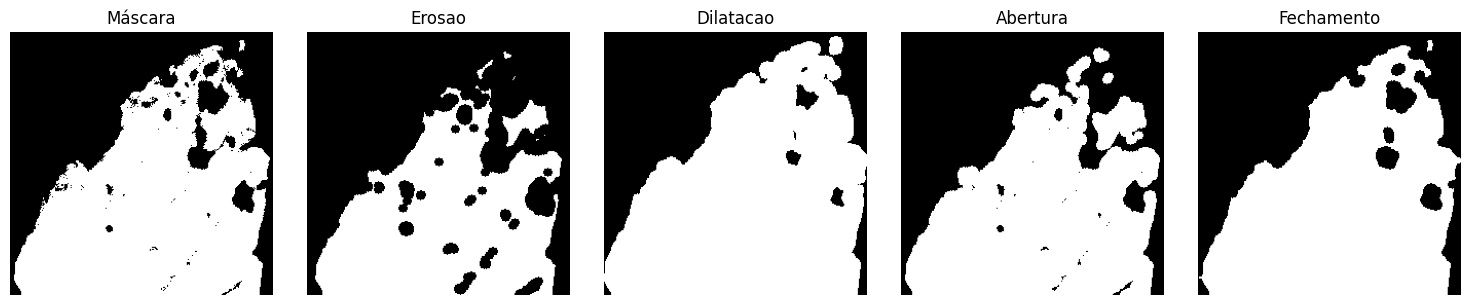

In [5]:
k = kernel(9, 'elipse')
ops = operadores_basicos(mask, k)
mostrar([('Máscara', mask)] + [(n.capitalize(), m) for n, m in ops.items()], cols=5)

- **Erosão** encolhe a folha e aumenta os buracos.
- **Dilatação** expande a folha e fecha buracos pequenos, mas “engorda” o contorno.
- **Abertura** (erosão → dilatação) remove ruído pequeno sem mudar muito o tamanho.
- **Fechamento** (dilatação → erosão) fecha buracos e fendas sem mudar muito o tamanho.

## 4. Efeito do tamanho do elemento estruturante

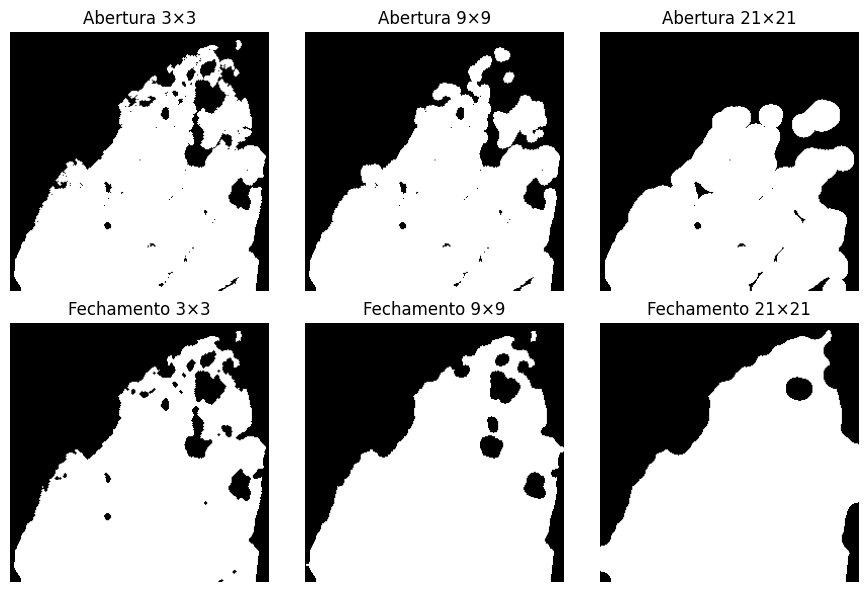

In [6]:
mostrar([(f'{n} {t}×{t}', cv2.morphologyEx(mask, op, kernel(t)))
         for op, n in ((cv2.MORPH_OPEN, 'Abertura'), (cv2.MORPH_CLOSE, 'Fechamento'))
         for t in (3, 9, 21)], cols=3)

## 5. Pipeline de limpeza da máscara
Abertura → fechamento → preenchimento de buracos → maior componente conexo.

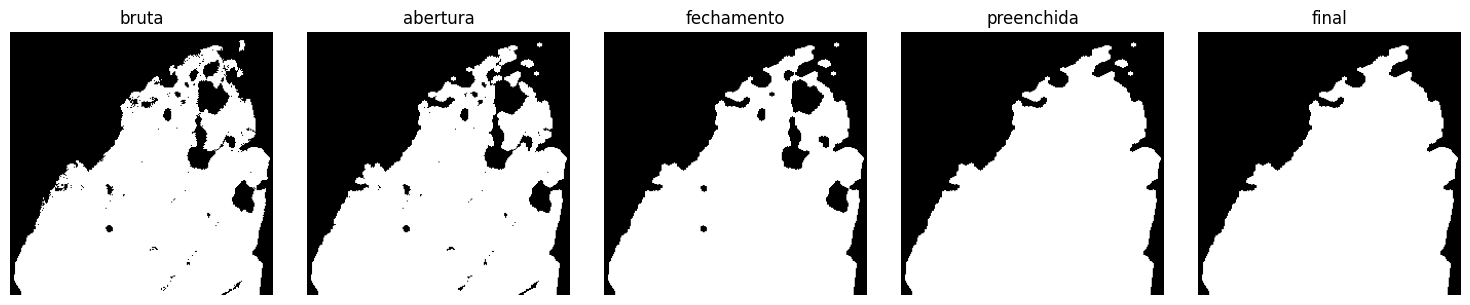

bruta       componentes = 5
abertura    componentes = 6
fechamento  componentes = 4
preenchida  componentes = 4
final       componentes = 1


In [7]:
etapas = limpar_mascara(mask, kernel(5, 'elipse'))
mostrar([(n, m) for n, m in etapas.items()], cols=5)
for n, m in etapas.items():
    print(f'{n:11s} componentes = {n_componentes(m)}')

## 6. Segmentação das lesões
Tecido verde = Otsu no canal a\*. Lesões = folha **E NÃO** verde, com abertura 3×3 e descarte de regiões < 15 px.

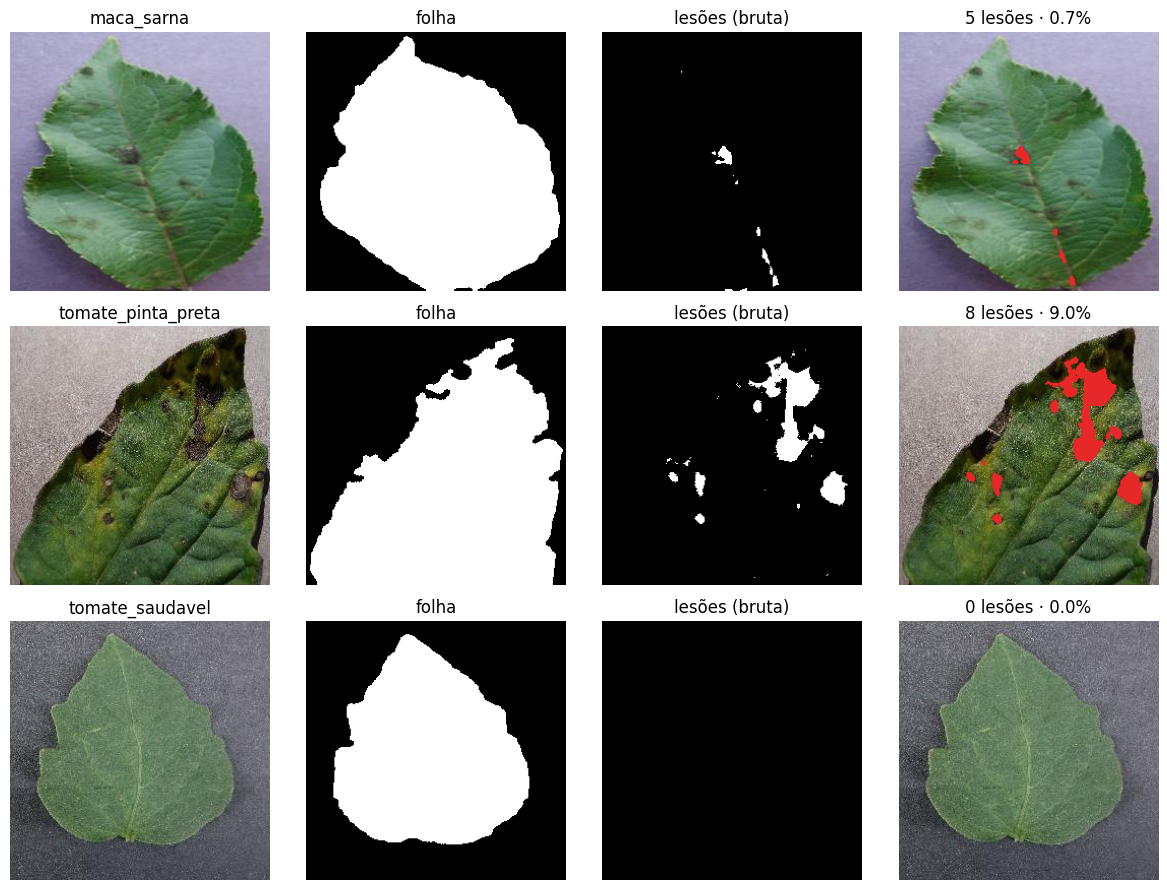

In [8]:
paineis = []
for c in classes:
    img = cv2.imread(f'../data/color/{c}/0001.jpg')
    folha = limpar_mascara(binarizar_folha(img), kernel(5))['final']
    les = segmentar_lesoes(binarizar_verde(img), folha, kernel(3))
    over = rgb(img).copy(); over[les['limpa'] > 0] = (230, 40, 40)
    paineis += [(c, rgb(img)), ('folha', folha), ('lesões (bruta)', les['bruta']),
                (f"{les['n_lesoes']} lesões · {pct_area(les['limpa'], folha):.1f}%", over)]
mostrar(paineis, cols=4)

## 7. Métricas em toda a amostra
Geradas na seção 0 por `scripts/gerar_resultados.py`.

In [9]:
import pandas as pd
df = pd.read_csv('../resultados/metricas.csv')
df.groupby('classe')[['iou_bruta', 'iou_limpa', 'comp_bruta', 'comp_limpa', 'n_lesoes', 'pct_lesao']].mean().round(3)

,iou_bruta,iou_limpa,comp_bruta,comp_limpa,n_lesoes,pct_lesao
classe,,,,,,
maca_sarna,0.947,0.955,3.052,1.0,6.743,1.821
tomate_pinta_preta,0.876,0.893,13.890,1.0,8.348,8.001
tomate_saudavel,0.958,0.960,3.149,1.0,0.975,0.324


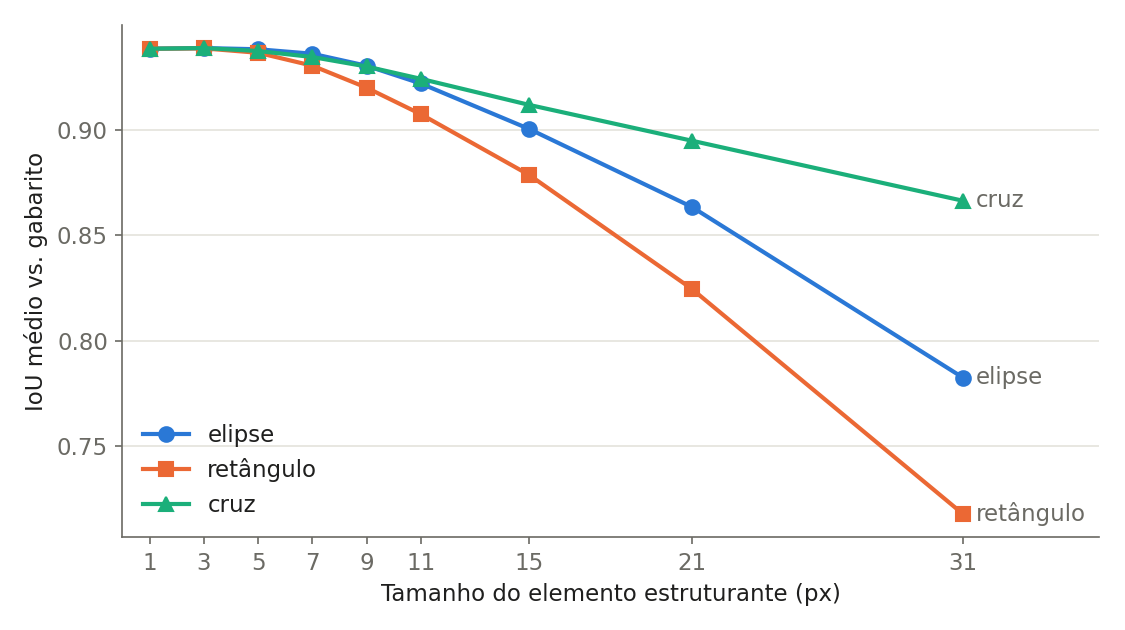

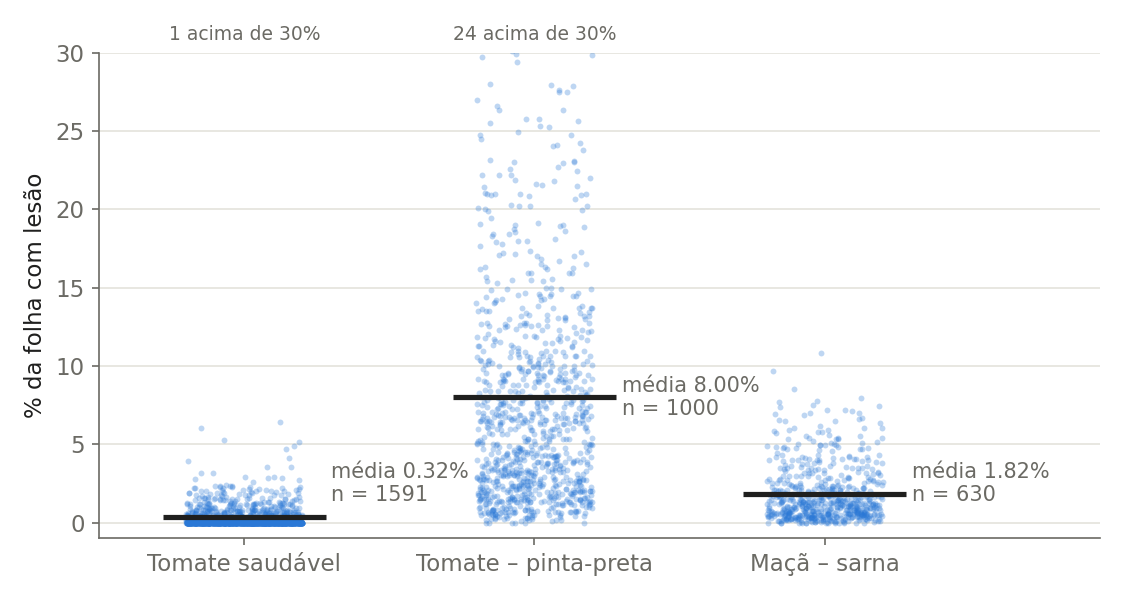

In [10]:
from IPython.display import Image, display
display(Image('../resultados/fig4_iou_kernel.png', width=650))
display(Image('../resultados/fig5_lesoes_por_classe.png', width=650))

## 8. Observações
- A limpeza morfológica reduz a máscara de 6,5 componentes em média para **1** (a folha) em todas as 3.221 imagens; o IoU médio sobe de 0,930 para 0,938.
- Elementos estruturantes **pequenos (3–7 px)** são os melhores (elipse 3×3: 0,9388; a 5×5 usada: 0,9382); acima disso o IoU cai, porque as pontas e os dentes da folha são apagados. Com 1×1 o IoU já é 0,9385: o ganho vem do **preenchimento de buracos e do maior componente**; abertura e fechamento limpam ruído e unem pedaços antes deles. A **cruz** degrada menos que o retângulo.
- A % de área lesionada já separa folhas saudáveis (média 0,32%) de doentes (pinta-preta 8,00%; sarna 1,82%).
- **Limitações:** lesões escuras na borda da folha não são detectadas; na maçã, a nervura central é confundida com lesão (a regra de forma da seção 9 resolve parte disso) e as manchas de sarna (verde-oliva) quase não aparecem.

## 9. Reconhecimento de formas
A morfologia também é usada para **reconhecer formas**, em três níveis:

1. **Cada região candidata** recebe descritores: área, circularidade (4πA/P²), solidez (A / área do fecho convexo),
   alongamento (razão dos eixos principais), espessura (2 × máximo da transformada de distância) e fração que **sobrevive a uma abertura 5×5**.
2. **Regra de forma:** região fina (no máximo 35% da área sobrevive à abertura 5×5, ou espessura ≤ 7 px) **e** alongada (≥ 3) → **nervura**; o resto → **mancha**.
3. **Folha inteira:** quantidade, tamanho e forma das manchas, **granulometria** (área que sobrevive a aberturas de raio 1–8 = espectro de padrões)
   e forma da folha (circularidade, solidez, alongamento e recortes medidos pelo fechamento).
   Esses atributos alimentam uma **árvore de decisão** de profundidade ≤ 4 (regras legíveis), avaliada com validação cruzada 5-fold.

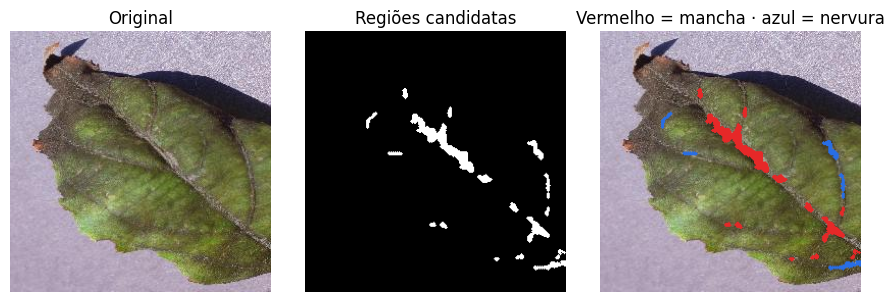

,area,circularidade,solidez,alongamento,espessura,sobrevive_abertura,tipo
3,816,0.18,0.58,5.25,10.95,0.96,mancha
10,230,0.34,0.61,1.26,10.13,0.87,mancha
16,144,0.25,0.66,5.78,6.56,0.65,nervura
4,123,0.45,0.78,3.24,6.56,0.84,nervura
7,82,0.79,0.91,1.82,7.64,0.89,mancha
6,77,0.28,0.68,6.64,4.65,0.00,nervura
2,60,0.43,0.72,3.92,3.82,0.00,nervura
8,54,0.83,0.92,1.75,6.56,0.83,mancha
5,48,0.49,0.89,4.03,3.82,0.00,nervura
0,44,0.85,0.90,2.07,5.48,0.50,mancha


In [11]:
import pandas as pd
from formas import classificar_regioes, atributos_folha

img = cv2.imread('../data/color/maca_sarna/0413.jpg')
folha = limpar_mascara(binarizar_folha(img), kernel(5))['final']
les = segmentar_lesoes(binarizar_verde(img), folha, kernel(3))['limpa']
manchas, nervuras, regioes = classificar_regioes(les)
over = rgb(img).copy(); over[manchas > 0] = (230, 40, 40); over[nervuras > 0] = (40, 110, 230)
mostrar([('Original', rgb(img)), ('Regiões candidatas', les), ('Vermelho = mancha · azul = nervura', over)], cols=3)
pd.DataFrame(regioes).round(2).sort_values('area', ascending=False)

In [12]:
at, _, _ = atributos_folha(folha, les)
pd.Series(at).round(3)

n_manchas                 12.000
n_nervuras                 5.000
pct_manchas                4.685
pct_nervuras               1.468
area_media_mancha        120.250
maior_mancha_pct           2.649
circularidade_manchas      0.382
solidez_manchas            0.671
alongamento_manchas        3.699
granulo_r1                 1.000
granulo_r2                 0.807
granulo_r3                 0.629
granulo_r5                 0.062
granulo_r8                 0.000
folha_circularidade        0.487
folha_solidez              0.916
folha_alongamento          1.379
folha_recortes             0.016
dtype: float64

### Resultado da classificação (3.221 folhas)
Atributos extraídos na seção 0 por `scripts/reconhecer_formas.py` (em cache em `resultados/formas_folhas.csv`).

Forma das lesões   acurácia  76.6%   balanceada  75.2%
Forma da folha     acurácia  66.6%   balanceada  69.4%
Lesões + folha     acurácia  86.0%   balanceada  85.0%
Só tomate (forma das lesões): 93.9%
Regra única: doente se % de manchas >= 0.41% -> 86.6%


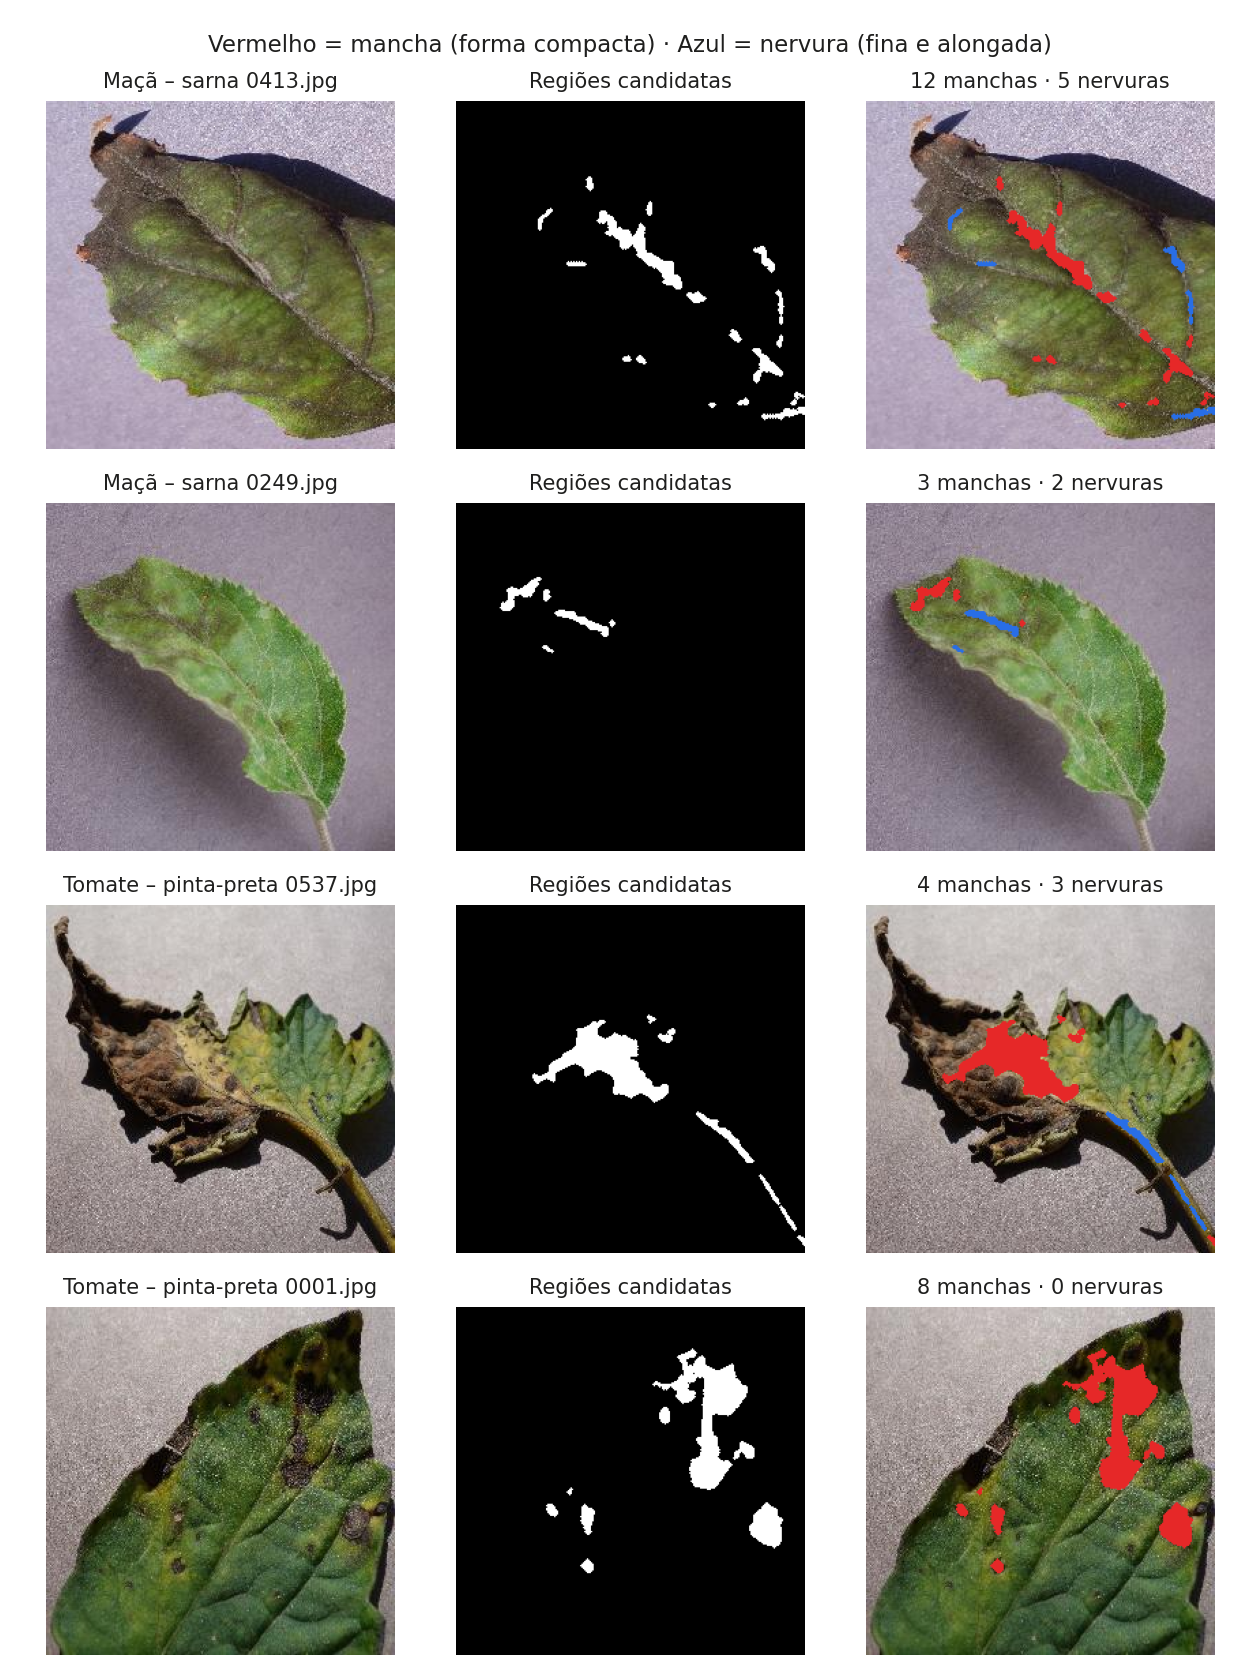

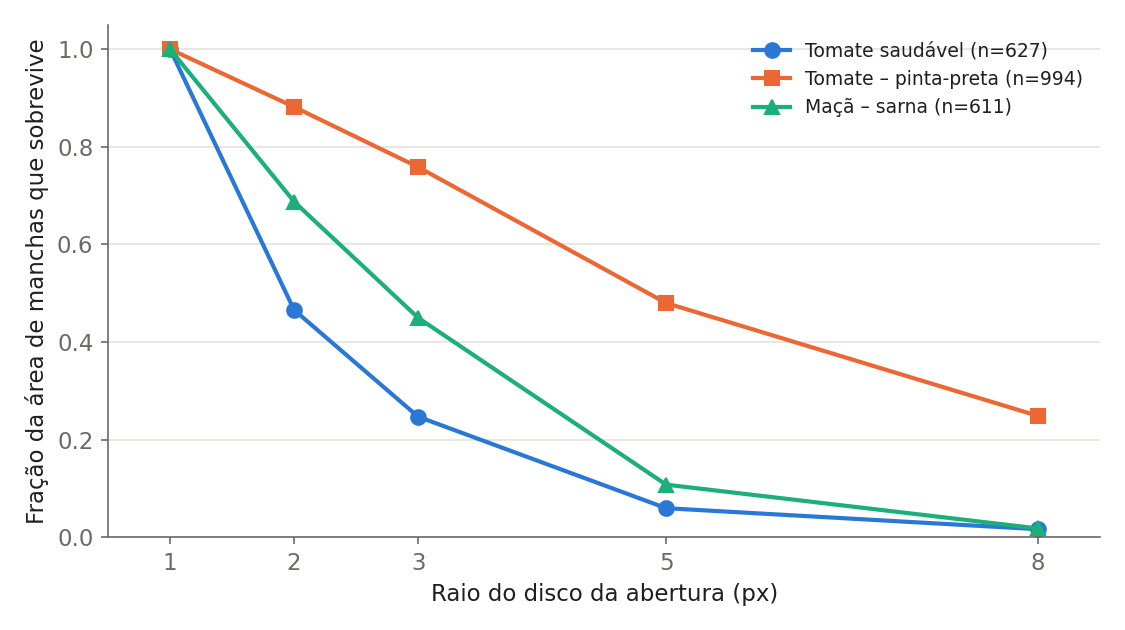

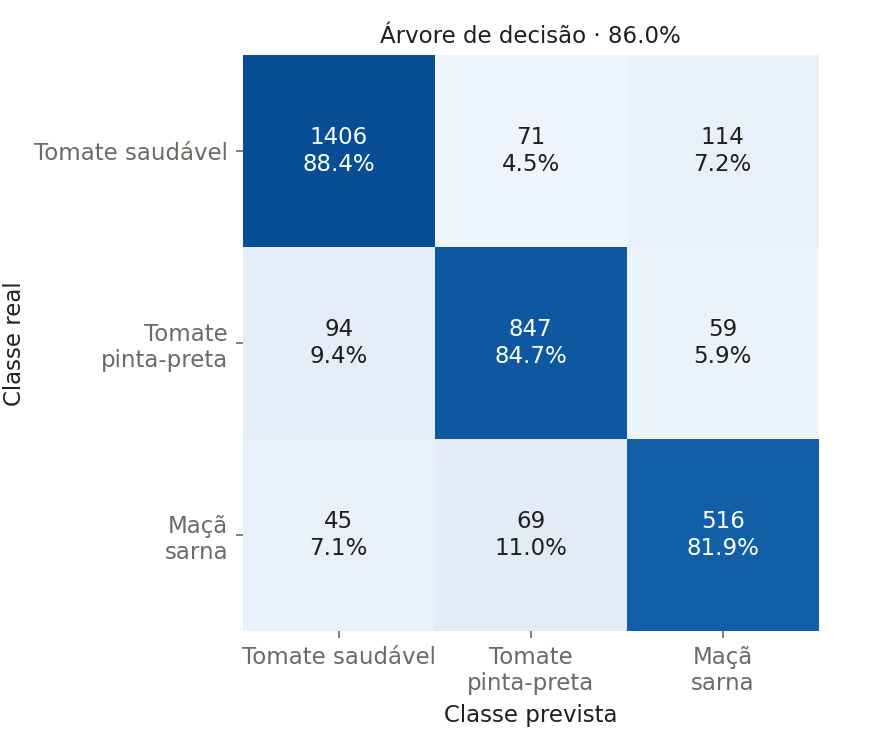

In [13]:
sys.path.insert(0, os.path.abspath('../scripts'))
from reconhecer_formas import classificar
from IPython.display import Image, display

r = classificar(pd.read_csv('../resultados/formas_folhas.csv'))
for nome, (acc, bal) in r['grupos'].items():
    print(f'{nome:18s} acurácia {100 * acc:5.1f}%   balanceada {100 * bal:5.1f}%')
print(f"Só tomate (forma das lesões): {100 * r['acc_tomate']:.1f}%")
print(f"Regra única: doente se % de manchas >= {r['limiar']:.2f}% -> {100 * r['acc_regra']:.1f}%")
for f in ('fig6_formas_regioes.png', 'fig7_granulometria.png', 'fig8_matriz_confusao.png'):
    display(Image(f'../resultados/{f}', width=600))

## 10. Relatório em PDF
Gera `resultados/relatorio.pdf` (8 páginas: objetivo, dados, método, tabelas e as 8 figuras). O mesmo que `python scripts/gerar_relatorio.py`.

In [14]:
from gerar_relatorio import gerar
print('Relatório salvo em:', os.path.relpath(gerar('Samuel Cassiano dos Santos')))

avaliando a classificação para o relatório...


Relatório salvo em: ../resultados/relatorio.pdf
